# Quantum query algorithms on a laptop

## 0. Imports

We can install the `query-complexity` package from pip:

```bash
pip install query-complexity
```

MOSEK is strongly recommended, otherwise the SDP doesn't always converge

In [6]:
import query_complexity as qc

In [7]:
#import importlib
import math
#import sys
import time
#from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

# Pick an installed CVXPY solver if CVXPY is available.
def pick_solver(preferred=("MOSEK", "SDPA", "SCS", "CLARABEL")):
    try:
        import cvxpy as cp
        installed = set(cp.installed_solvers())
        for solver in preferred:
            if solver in installed:
                return solver
    except Exception as exc:
        print("CVXPY solver detection failed:", repr(exc))
    return None

SOLVER = pick_solver()
print("Selected solver:", SOLVER)

# Small benchmark ranges by default. Increase after validating your solver.
OR_SDP_NS = list(range(1, 10))          # symmetric value SDP: n=2,...,8
OR_TRANSDUCER_NS = list(range(2, 11))   # full-input transducer: exponential in n columns

def time_call(fn, *args, **kwargs):
    t0 = time.perf_counter()
    out = fn(*args, **kwargs)
    return out, time.perf_counter() - t0

Selected solver: MOSEK


## 1. Symmetric OR value SDP performance

**Adversary SDP with our symmetry reduction methods**                n,
                qc.OR_layers(n),

for computing query_complexity of OR_n: 

```python
qc.solve_symmetric_value(n, qc.OR_layers(n))
```

,n,expected,solver,time_sec,value,abs_error,status,num_psd_cones,num_blocks,psd_cone_sizes
0,5,2.236068,MOSEK,0.020555,2.236068,1.005670e-07,optimal,1,13,[6]
1,10,3.162278,MOSEK,0.041254,3.162278,4.957301e-10,optimal,1,50,[11]
2,15,3.872983,MOSEK,0.196056,3.872983,2.670941e-08,optimal,1,113,[16]
3,20,4.472136,MOSEK,0.171383,4.472136,5.094682e-08,optimal,1,200,[21]
4,25,5.000000,MOSEK,0.423723,5.000000,1.630589e-07,optimal,1,313,[26]
5,30,5.477226,MOSEK,0.618446,5.477226,3.548295e-07,optimal,1,450,[31]
6,35,5.916080,MOSEK,1.083476,5.916080,8.735810e-08,optimal,1,613,[36]
7,40,6.324555,MOSEK,1.260540,6.324556,1.020982e-06,optimal,1,800,[41]
8,45,6.708204,MOSEK,1.979098,6.708205,8.705236e-07,optimal,1,1013,[46]


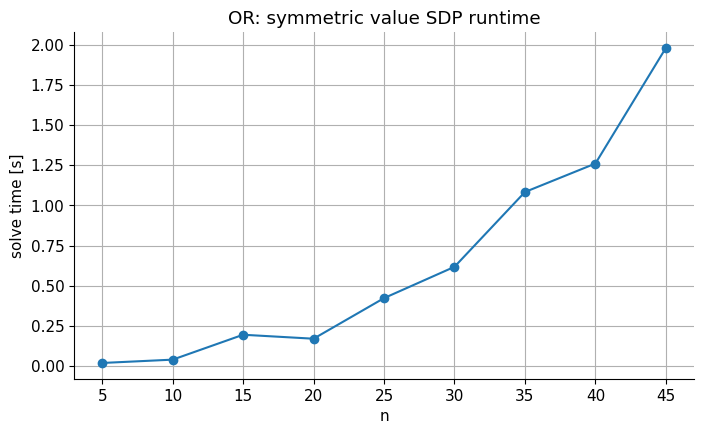

In [8]:
def benchmark_or_symmetric_value(ns=OR_SDP_NS, solver=SOLVER):
    rows = []
    for n in ns:
        n=5*n
        row = {"n": n, "expected": math.sqrt(n), "solver": solver}
        try:
            res, elapsed = time_call(
                qc.solve_symmetric_value,
                n,
                qc.OR_layers(n),
                solver=solver,
                verbose=False,
            )
            row.update({
                "time_sec": elapsed,
                "value": float(res["value"]),
                "abs_error": abs(float(res["value"]) - math.sqrt(n)),
                "status": res.get("status"),
                "num_psd_cones": res.get("num_psd_cones"),
                "num_blocks": res.get("num_blocks"),
                "psd_cone_sizes": str(res.get("psd_cone_sizes")),
            })
        except Exception as exc:
            row.update({
                "time_sec": np.nan,
                "value": np.nan,
                "abs_error": np.nan,
                "status": "ERROR",
                "error": repr(exc),
            })
        rows.append(row)
    return pd.DataFrame(rows)

or_sdp_df = benchmark_or_symmetric_value()
display(or_sdp_df)

success = or_sdp_df[or_sdp_df["status"].astype(str).str.contains("optimal", case=False, na=False)]

fig, ax = plt.subplots()
if not success.empty:
    ax.plot(success["n"], success["time_sec"], marker="o")
    ax.set_xlabel("n")
    ax.set_ylabel("solve time [s]")
    ax.set_title("OR: symmetric value SDP runtime")
else:
    ax.text(0.5, 0.5, "No successful SDP solves. Check CVXPY/solver install.", ha="center", va="center")
    ax.set_axis_off()
plt.show()

## 2. Transducer construction performance for OR

We retrieve the SDP solution from the analytical formula, then we call the `build_adversary_transducer`

```python
sol = qc.analytic_or_solution(n)
td = qc.build_adversary_transducer(sol)
```

,n,num_inputs,analytic_solution_time_sec,transducer_build_time_sec,public_dim,private_dim,total_dim,W,expected_W,map_error,unitarity_error
0,2,4,0.000089,0.000608,2,2,4,0.707107,0.707107,7.318650e-16,1.073496e-15
1,3,8,0.000047,0.000517,2,3,5,0.866025,0.866025,1.265870e-15,1.322744e-15
2,4,16,0.000072,0.000849,2,4,6,1.000000,1.000000,1.988227e-15,1.120462e-15
3,5,32,0.000142,0.001219,2,5,7,1.118034,1.118034,2.023840e-15,1.875751e-15
4,6,64,0.000332,0.002056,2,6,8,1.224745,1.224745,7.182488e-15,1.737575e-15
5,7,128,0.000782,0.237694,2,7,9,1.322876,1.322876,2.260513e-14,2.429300e-15
6,8,256,0.003765,0.327316,2,8,10,1.414214,1.414214,6.770820e-15,2.685248e-15
7,9,512,0.012837,0.443092,2,9,11,1.500000,1.500000,5.018197e-14,4.224335e-15
8,10,1024,0.050871,0.467797,2,10,12,1.581139,1.581139,6.221811e-14,4.028277e-15


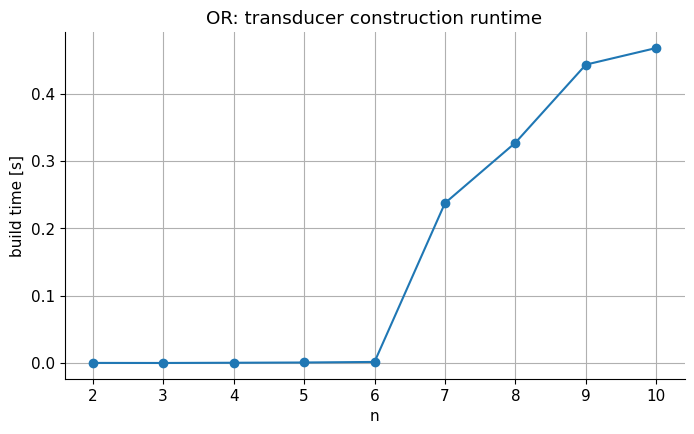

In [9]:
def benchmark_or_transducer(ns=OR_TRANSDUCER_NS):
    rows = []
    for n in ns:
        row = {"n": n, "num_inputs": 2**n}
        try:
            sol, t_sol = time_call(qc.analytic_or_solution, n)
            td, t_td = time_call(qc.build_adversary_transducer, sol)
            W = qc.catalyst_norm_bound(td)
            row.update({
                "analytic_solution_time_sec": t_sol,
                "transducer_build_time_sec": t_td,
                "public_dim": td.public_dim,
                "private_dim": td.private_dim,
                "total_dim": td.public_dim + td.private_dim,
                "W": W,
                "expected_W": math.sqrt(n) / 2,
                "map_error": td.map_error,
                "unitarity_error": td.unity_error if hasattr(td, "unity_error") else td.unitarity_error,
            })
        except Exception as exc:
            row.update({
                "transducer_build_time_sec": np.nan,
                "status": "ERROR",
                "error": repr(exc),
            })
        rows.append(row)
    return pd.DataFrame(rows)

or_td_df = benchmark_or_transducer()
display(or_td_df)

good_td = or_td_df.dropna(subset=["transducer_build_time_sec"])

fig, ax = plt.subplots()
if not good_td.empty:
    ax.plot(good_td["n"], good_td["transducer_build_time_sec"], marker="o")
    ax.set_xlabel("n")
    ax.set_ylabel("build time [s]")
    ax.set_title("OR: transducer construction runtime")
else:
    ax.text(0.5, 0.5, "No successful transducer builds.", ha="center", va="center")
    ax.set_axis_off()
plt.show()


## 3. Algorithm from transducer

We fix the number of oracle calls `K`

```python
K = qc.choose_repetitions
```

And we can compute the output probabilities with

```python
qc.run_adversary_algorithm
```

epsilon = 0.9
K = 5
theoretical vector-error bound <= 0.8323582900575633


,x,f(x),P(0),P(1),error_probability,garbage_norm
0,000,0,0.683985,0.029917,0.316015,0.534881
1,100,1,0.028963,0.688591,0.311409,0.531456
2,110,1,0.008216,0.826934,0.173066,0.406017
3,111,1,0.003343,0.887713,0.112287,0.330067


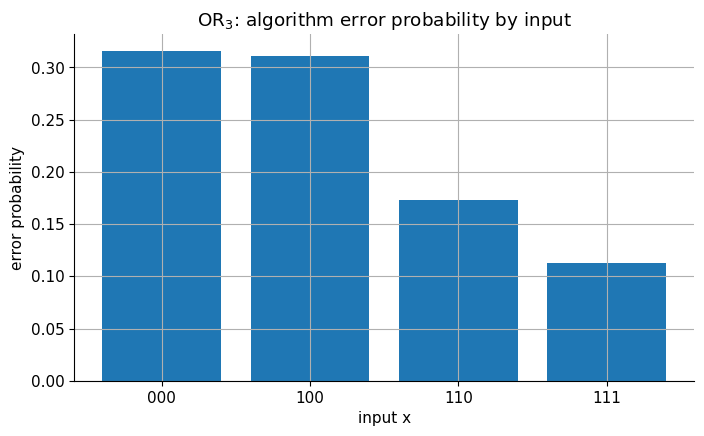

In [11]:
def catalyst_matrix(solution):
    # Rows are inputs; columns are the concatenated private catalyst entries.
    pieces = [Z / np.sqrt(2.0) for Z in solution.z]
    return np.concatenate(pieces, axis=1) if pieces else np.zeros((len(solution.inputs), 0))

n = 3
sol_or3 = qc.analytic_or_solution(n)
td_or3 = qc.build_adversary_transducer(sol_or3)
W_or3 = qc.catalyst_norm_bound(td_or3)

epsilon = 0.9
K = qc.choose_repetitions(W_or3, epsilon)
print("epsilon =", epsilon)
print("K =", K)
print("theoretical vector-error bound <=", 2 * math.sqrt(W_or3 / K))

selected_inputs = [
    (0, 0, 0),
    (1, 0, 0),
    (1, 1, 0),
    (1, 1, 1),
]

algo_rows = []
for x in selected_inputs:
    result = qc.run_adversary_algorithm(td_or3, x, K)
    probs = np.asarray(result["output_probabilities"], dtype=float)
    true_y = int(any(x))
    err = 1.0 - probs[true_y]
    algo_rows.append({
        "x": "".join(map(str, x)),
        "f(x)": true_y,
        "P(0)": probs[0] if len(probs) > 0 else np.nan,
        "P(1)": probs[1] if len(probs) > 1 else np.nan,
        "error_probability": err,
        "garbage_norm": float(result["garbage_norm"]),
    })

algo_df = pd.DataFrame(algo_rows)
display(algo_df)

xlabels = algo_df["x"].tolist()

fig, ax = plt.subplots()
ax.bar(xlabels, algo_df["error_probability"])
ax.set_xlabel("input x")
ax.set_ylabel("error probability")
ax.set_title(r"OR$_3$: algorithm error probability by input")
plt.show()

## 4. Algorithm on qiskit

For a certain input `x`, we can export the algorithm on qiskit, and look at its gate-decomposition

```python
qcirq = qc.qiskit_oracle_separated_circuit(transducer, x, K)
```

And then decompose it into gates

```python
qcirc.decompose()
```

In [ ]:
def qiskit_oracle_separated_circuit(td, x, K, measure_all=False):
    # Build a Qiskit circuit with separate Spread, Oracle[slot], U[slot], Unspread gates.
    from qiskit import QuantumCircuit
    from qiskit.circuit.library import UnitaryGate

    h, l = td.public_dim, td.private_dim
    Qx = qc.adversary_query(td, x)
    U = td.U

    logical_dim = K * h + l
    padded_dim = qc.next_power_of_two(logical_dim)
    num_qubits = int(np.log2(padded_dim))

    circ = QuantumCircuit(num_qubits)
    qubits = list(range(num_qubits))

    def append_logical(M, label):
        padded = np.eye(padded_dim, dtype=complex)
        padded[:logical_dim, :logical_dim] = np.asarray(M, dtype=complex)
        circ.append(UnitaryGate(padded, label=label), qubits)

    Spread = qc.public_spread(h, l, K)
    append_logical(Spread, "Spread")
    for slot in range(K):
        append_logical(qc.lift_step_to_slot(Qx, h, l, K, slot), f"Oracle[{slot}]")
        append_logical(qc.lift_step_to_slot(U, h, l, K, slot), f"U[{slot}]")
    append_logical(Spread.conj().T, "Unspread")

    if measure_all:
        circ.measure_all()

    meta = {
        "logical_dim": logical_dim,
        "padded_dim": padded_dim,
        "num_qubits": num_qubits,
        "public_dim": h,
        "private_dim": l,
        "K": K,
        "oracle_calls": K,
    }
    return circ, meta

try:
    import qiskit
    from qiskit.quantum_info import Statevector

    sol_or2 = qc.analytic_or_solution(2)
    td_or2 = qc.build_adversary_transducer(sol_or2)

    x = (1, 0)
    K_qiskit = 1

    t0 = time.perf_counter()
    qcirc, meta = qiskit_oracle_separated_circuit(td_or2, x, K_qiskit)
    qiskit_build_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    sv = Statevector.from_instruction(qcirc)
    sim_time = time.perf_counter() - t0

    decoded = qc.decode_statevector(sv, public_dim=meta["public_dim"], logical_dim=meta["logical_dim"])

    print("Qiskit version:", qiskit.__version__)
    print("input x:", x)
    print("metadata:", meta)
    print("circuit build time:", qiskit_build_time)
    print("statevector simulation time:", sim_time)
    print("output decoding:", decoded)
    print("top-level circuit ops:", qcirc.count_ops())
    print("top-level depth:", qcirc.depth())

    display(qcirc.draw("text"))

except Exception as exc:
    qcirc = None
    meta = None
    print("Qiskit section skipped:", repr(exc))
    print("Install qiskit with: pip install qiskit pylatexenc")

Qiskit version: 2.2.3
input x: (1, 0)
metadata: {'logical_dim': 4, 'padded_dim': 4, 'num_qubits': 2, 'public_dim': 2, 'private_dim': 2, 'K': 1, 'oracle_calls': 1}
circuit build time: 0.011640855998848565
statevector simulation time: 0.005732460000217543
output decoding: {'output_probabilities': array([0.17157288, 0.34314575]), 'garbage_probability': 0.4852813742385705, 'padding_probability': 0.0, 'total_probability': 0.9999999999999998}
top-level circuit ops: OrderedDict({'unitary': 4})
top-level depth: 4


┌─────────┐┌────────────┐┌───────┐┌───────────┐
q_0: ┤0        ├┤0           ├┤0      ├┤0          ├
     │  Spread ││  Oracle[0] ││  U[0] ││  Unspread │
q_1: ┤1        ├┤1           ├┤1      ├┤1          ├
     └─────────┘└────────────┘└───────┘└───────────┘

In [ ]:
# Gate decomposition and visual gate-count summary.
if qcirc is not None:
    try:
        decomp = qcirc.decompose(reps=2)
        print("decomposed ops:", decomp.count_ops())
        print("decomposed depth:", decomp.depth())
        display(decomp.draw("text"))

        ops = decomp.count_ops()
    except Exception as exc:
        print("Decomposition failed:", repr(exc))

decomposed ops: OrderedDict({'u': 10, 'cx': 3})
decomposed depth: 8


global phase: 2.2345
     ┌────────────────────┐     ┌──────────────────────┐»
q_0: ┤ U(π,1.4066,-1.735) ├──■──┤ U(π,-2.1588,-2.1588) ├»
     ├───────────────────┬┘┌─┴─┐└┬───────────────────┬─┘»
q_1: ┤ U(π/2,-π,-2.9895) ├─┤ X ├─┤ U(π/2,-0.15207,0) ├──»
     └───────────────────┘ └───┘ └───────────────────┘  »
«     ┌───────────────────────┐        ┌───────────────────┐         »
«q_0: ┤ U(0,0.41241,-0.41241) ├──■─────┤ U(1.7432,-π,-π/2) ├──────■──»
«     └──┬──────────────────┬─┘┌─┴─┐┌──┴───────────────────┴───┐┌─┴─┐»
«q_1: ───┤ U(1.2463,-π/2,0) ├──┤ X ├┤ U(1.7211,1.7246,-3.1184) ├┤ X ├»
«        └──────────────────┘  └───┘└──────────────────────────┘└───┘»
«      ┌───────────────────┐ 
«q_0: ─┤ U(0,-1.737,1.737) ├─
«     ┌┴───────────────────┴┐
«q_1: ┤ U(1.4187,-π/2,-π/2) ├
«     └─────────────────────┘